# 01. Predictive-statistics vertical slice

This notebook visualizes the deterministic mock validation. It is an implementation test, not an astrophysical result.

In [1]:
from pathlib import Path
import json
import os
import pandas as pd
import matplotlib.pyplot as plt

path = Path(os.environ["GWTC_RESULTS_ROOT"]) / "pilot" / "toy_validation" / "toy_validation.json"
report = json.loads(path.read_text())
report["status"], report["comparisons"]

('PASS',
 {'delta_peak_minus_break': 2.775486444739979,
  'delta_peak_minus_smooth': 6.635042605363722})

In [2]:
score_table = pd.DataFrame(
    {name: {k: v for k, v in item.items() if k != "steps"}
     for name, item in report["models"].items()}
).T
score_table

,event_ess_summary,hyperposterior_draw_bootstrap,joint_log_score,joint_prequential_absolute_difference,leave_one_event_out_influence,minimum_event_ess,minimum_selection_ess,name,prequential_log_score,selection_ess_summary
break,"{'maximum': 599.1802521482908, 'median': 595.9...","{'mean': 16.754517596490242, 'median': 16.7615...",16.762245,0.0,"[{'event_id': 'ToyO4a_001', 'full_log_score': ...",574.714742,9836.613634,break,16.762245,"{'maximum': 17372.191355577408, 'median': 1342..."
peak,"{'maximum': 598.3967367043988, 'median': 537.0...","{'mean': 19.523540270270566, 'median': 19.5173...",19.537731,0.0,"[{'event_id': 'ToyO4a_001', 'full_log_score': ...",168.61556,4823.169995,peak,19.537731,"{'maximum': 8422.950565898751, 'median': 6908...."
smooth,"{'maximum': 599.2403710699061, 'median': 596.6...","{'mean': 12.901205615536247, 'median': 12.9030...",12.902688,0.0,"[{'event_id': 'ToyO4a_001', 'full_log_score': ...",550.558043,6209.548718,smooth,12.902688,"{'maximum': 18347.34038135878, 'median': 10939..."


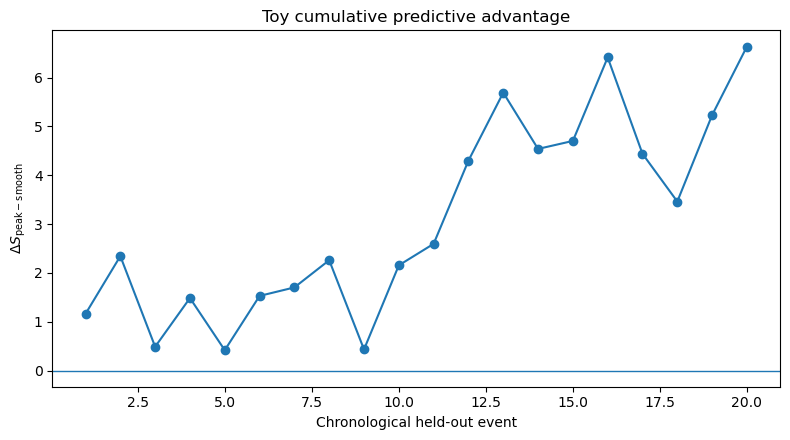

In [3]:
steps = {}
for name, item in report["models"].items():
    frame = pd.DataFrame(item["steps"])
    steps[name] = frame
delta = steps["peak"]["cumulative_log_score"] - steps["smooth"]["cumulative_log_score"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(delta) + 1), delta, marker="o")
ax.axhline(0.0, linewidth=1)
ax.set_xlabel("Chronological held-out event")
ax.set_ylabel(r"$\Delta S_{\rm peak-smooth}$")
ax.set_title("Toy cumulative predictive advantage")
fig.tight_layout()

In [4]:
pd.DataFrame({
    "event_id": steps["peak"]["event_id"],
    "run": steps["peak"]["run"],
    "delta_increment_peak_smooth": (
        steps["peak"]["log_score_increment"]
        - steps["smooth"]["log_score_increment"]
    ),
    "cumulative_delta_peak_smooth": delta,
})

,event_id,run,delta_increment_peak_smooth,cumulative_delta_peak_smooth
0,ToyO4a_001,ToyO4a,1.160576,1.160576
1,ToyO4a_002,ToyO4a,1.182062,2.342638
2,ToyO4a_003,ToyO4a,-1.855716,0.486922
3,ToyO4a_004,ToyO4a,0.997237,1.484159
4,ToyO4a_005,ToyO4a,-1.067449,0.416710
5,ToyO4a_006,ToyO4a,1.111269,1.527979
6,ToyO4a_007,ToyO4a,0.173805,1.701784
7,ToyO4a_008,ToyO4a,0.557299,2.259083
8,ToyO4a_009,ToyO4a,-1.827124,0.431959
9,ToyO4a_010,ToyO4a,1.722485,2.154444
